In [7]:
import os
os.chdir(r"E:\AI\Car Purchase Prediction Model\car-recommender")

# Verify it worked
print("Working directory:", os.getcwd())

Working directory: E:\AI\Car Purchase Prediction Model\car-recommender


In [8]:
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

# ── Style ────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi": 120,
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})
sns.set_palette("husl")

# ── Load ─────────────────────────────────────────────────────────────────────
df = pl.read_parquet("data/processed/sample_500k.parquet")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns}")

Shape: (500000, 29)
Columns: ['vin', 'price', 'year', 'make_name', 'model_name', 'trim_name', 'body_type', 'mileage', 'fuel_type', 'engine_type', 'engine_cylinders', 'engine_displacement', 'transmission', 'wheel_system', 'horsepower', 'maximum_seating', 'city_fuel_economy', 'highway_fuel_economy', 'has_accidents', 'frame_damaged', 'fleet', 'salvage', 'theft_title', 'owner_count', 'dealer_zip', 'is_new', 'listed_date', 'latitude', 'longitude']


In [9]:
Price is ranging from $299 to $2,749,950. If I plot the histogram of this, it goes form low height to high height. When I take log price, it does down.

SyntaxError: invalid syntax (3717424853.py, line 1)

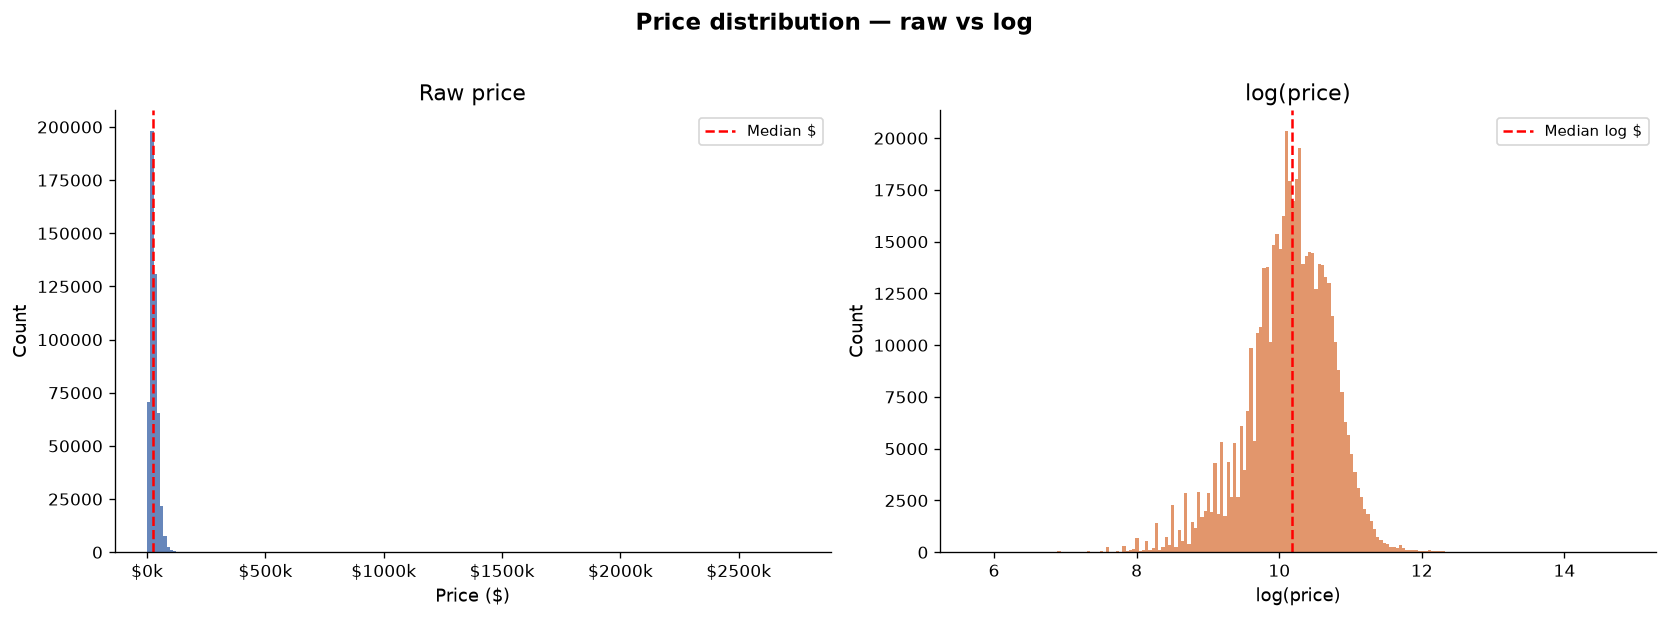

Raw  — median: $26,500  mean: $29,929  std: $19,625
Log  — median: 10.185  mean: 10.142  std: 0.600

Percentiles (raw price):
  p  1: $     4,495
  p  5: $     8,200
  p 25: $    18,458
  p 50: $    26,500
  p 75: $    38,243
  p 95: $    59,761
  p 99: $    83,920


In [10]:
# Convert to pandas for matplotlib (easier for multi-panel plots)
prices = df["price"].to_numpy()
log_prices = np.log(prices[prices > 0])  # guard against any zeros

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Raw price ────────────────────────────────────────────────────────────────
axes[0].hist(prices, bins=200, color="#4C72B0", edgecolor="none", alpha=0.85)
axes[0].set_title("Raw price")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Count")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"${x/1000:.0f}k"))

# ── Log price ────────────────────────────────────────────────────────────────
axes[1].hist(log_prices, bins=200, color="#DD8452", edgecolor="none", alpha=0.85)
axes[1].set_title("log(price)")
axes[1].set_xlabel("log(price)")
axes[1].set_ylabel("Count")

# Annotate with key stats
for ax, vals, label in [(axes[0], prices, "$"),
                         (axes[1], log_prices, "log $")]:
    ax.axvline(np.median(vals), color="red", lw=1.5,
               linestyle="--", label=f"Median {label}")
    ax.legend(fontsize=9)

plt.suptitle("Price distribution — raw vs log", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("docs/plot_price_distribution.png", bbox_inches="tight")
plt.show()

print(f"Raw  — median: ${np.median(prices):,.0f}  mean: ${np.mean(prices):,.0f}  "
      f"std: ${np.std(prices):,.0f}")
print(f"Log  — median: {np.median(log_prices):.3f}  mean: {np.mean(log_prices):.3f}  "
      f"std: {np.std(log_prices):.3f}")
print(f"\nPercentiles (raw price):")
for p in [1, 5, 25, 50, 75, 95, 99]:
    print(f"  p{p:3d}: ${np.percentile(prices, p):>10,.0f}")

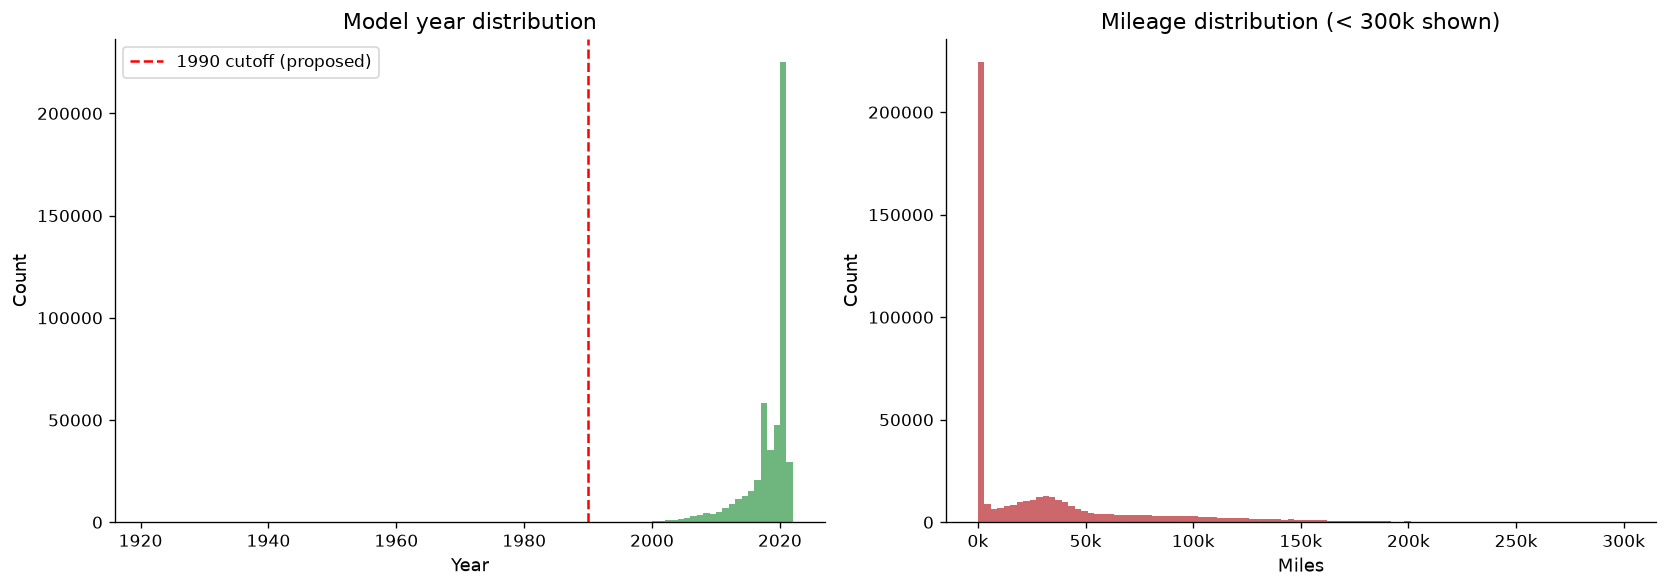

Rows with year < 1990:              844  (0.17%)
Rows with year > 2021:              0  (0.00%)
Used cars with 0 miles:             0
Mileage > 400k:                     4


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Year ─────────────────────────────────────────────────────────────────────
years = df["year"].to_numpy()
axes[0].hist(years, bins=range(int(years.min()), int(years.max())+2),
             color="#55A868", edgecolor="none", alpha=0.85)
axes[0].set_title("Model year distribution")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Count")
axes[0].axvline(1990, color="red", lw=1.5, linestyle="--", label="1990 cutoff (proposed)")
axes[0].legend()

# ── Mileage ──────────────────────────────────────────────────────────────────
miles = df["mileage"].drop_nulls().to_numpy()
axes[1].hist(miles[miles < 300_000], bins=100,
             color="#C44E52", edgecolor="none", alpha=0.85)
axes[1].set_title("Mileage distribution (< 300k shown)")
axes[1].set_xlabel("Miles")
axes[1].set_ylabel("Count")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x/1000:.0f}k"))

plt.tight_layout()
plt.savefig("docs/plot_year_mileage.png", bbox_inches="tight")
plt.show()

# How many rows does the 1990 cutoff remove?
pre1990 = (df["year"] < 1990).sum()
post2021 = (df["year"] > 2021).sum()
zero_miles_used = ((df["mileage"] == 0) & (~df["is_new"])).sum()
high_miles = (df["mileage"] > 400_000).sum()

print(f"Rows with year < 1990:              {pre1990:,}  ({pre1990/len(df)*100:.2f}%)")
print(f"Rows with year > 2021:              {post2021:,}  ({post2021/len(df)*100:.2f}%)")
print(f"Used cars with 0 miles:             {zero_miles_used:,}")
print(f"Mileage > 400k:                     {high_miles:,}")

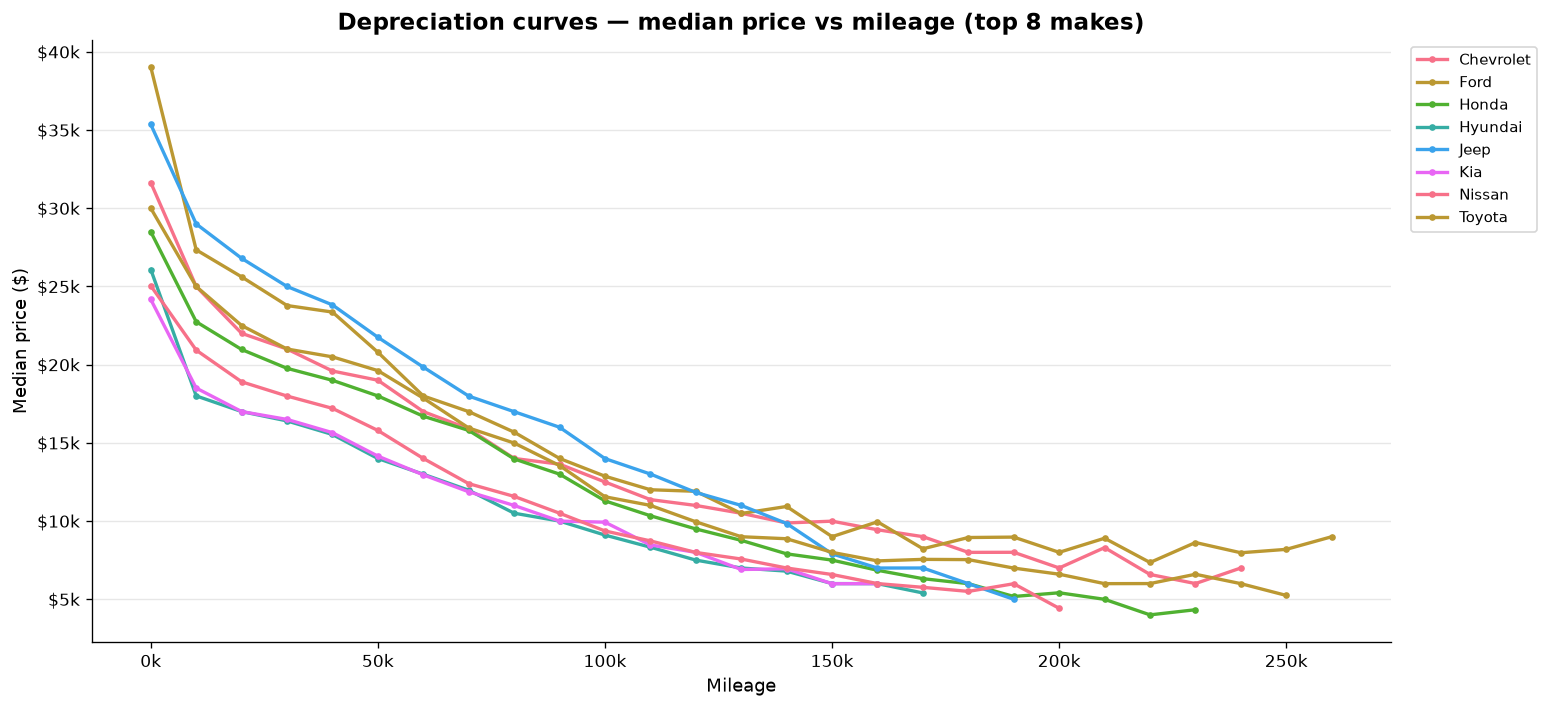

Mileage nulls dropped: 15,846

Top 8 makes:
make_name
Ford         78998
Chevrolet    62497
Toyota       40001
Nissan       36121
Honda        35783
Jeep         28047
Hyundai      22819
Kia          18814


In [13]:
pdf = df.select([
    "make_name", "model_name", "mileage", "price", "year", "is_new"
]).to_pandas()

top_makes = pdf["make_name"].value_counts().head(8).index.tolist()
pdf_top = pdf[pdf["make_name"].isin(top_makes)].copy()

# ── Fix: drop mileage nulls before binning ───────────────────────────────────
pdf_top = pdf_top.dropna(subset=["mileage"])
pdf_top["mileage_bin"] = (pdf_top["mileage"] // 10_000 * 10_000).astype(int)

bin_counts = pdf_top.groupby(["make_name", "mileage_bin"]).size()
valid_bins = bin_counts[bin_counts >= 30].reset_index()[["make_name","mileage_bin"]]
pdf_plot = pdf_top.merge(valid_bins, on=["make_name","mileage_bin"])

depr = (pdf_plot.groupby(["make_name","mileage_bin"])["price"]
        .median().reset_index())

fig, ax = plt.subplots(figsize=(13, 6))
for make, grp in depr.groupby("make_name"):
    grp = grp.sort_values("mileage_bin")
    ax.plot(grp["mileage_bin"], grp["price"], marker="o",
            markersize=3, linewidth=2, label=make)

ax.set_title("Depreciation curves — median price vs mileage (top 8 makes)",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Mileage")
ax.set_ylabel("Median price ($)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x/1000:.0f}k"))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"${x/1000:.0f}k"))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("docs/plot_depreciation_curves.png", bbox_inches="tight")
plt.show()

print(f"Mileage nulls dropped: {pdf[pdf['make_name'].isin(top_makes)]['mileage'].isna().sum():,}")
print("\nTop 8 makes:")
print(pdf["make_name"].value_counts().head(8).to_string())

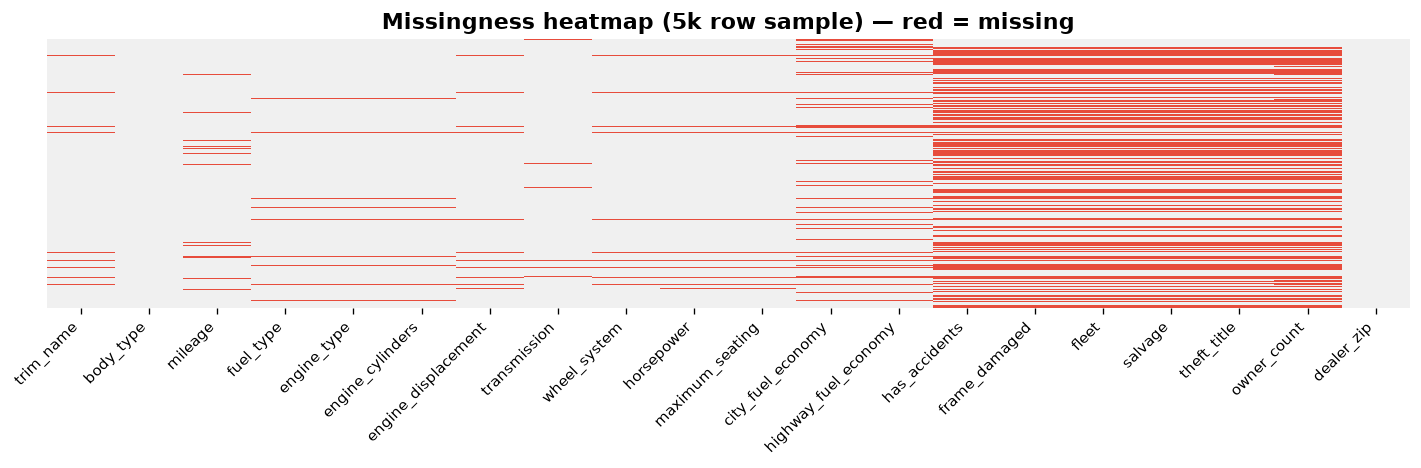

Null counts (columns with any nulls):
  owner_count               253,107  (50.6%)
  fleet                     238,098  (47.6%)
  frame_damaged             238,098  (47.6%)
  salvage                   238,098  (47.6%)
  has_accidents             238,098  (47.6%)
  theft_title               238,098  (47.6%)
  city_fuel_economy          81,985  (16.4%)
  highway_fuel_economy       81,985  (16.4%)
  engine_displacement        28,840  (5.8%)
  horsepower                 28,840  (5.8%)
  maximum_seating            26,642  (5.3%)
  wheel_system               24,509  (4.9%)
  mileage                    24,023  (4.8%)
  trim_name                  19,338  (3.9%)
  engine_type                16,774  (3.4%)
  engine_cylinders           16,774  (3.4%)
  fuel_type                  13,754  (2.8%)
  transmission               10,537  (2.1%)
  body_type                   2,246  (0.4%)
  dealer_zip                     31  (0.0%)


In [14]:
# Which columns are missing, and do nulls cluster together?
pdf_full = df.to_pandas()

# Only columns that have any nulls
null_cols = [c for c in pdf_full.columns 
             if pdf_full[c].isna().any()]

# Sample 5k rows for the heatmap (full 500k is too slow)
sample = pdf_full[null_cols].sample(5_000, random_state=42)

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(sample.isna(), 
            cbar=False, 
            yticklabels=False,
            xticklabels=null_cols,
            ax=ax,
            cmap=["#f0f0f0", "#e74c3c"])  # white=present, red=missing

ax.set_title("Missingness heatmap (5k row sample) — red = missing",
             fontsize=13, fontweight="bold")
ax.set_xticklabels(null_cols, rotation=45, ha="right", fontsize=9)
plt.tight_layout()
plt.savefig("docs/plot_missingness.png", bbox_inches="tight")
plt.show()

# Print exact null counts
print("Null counts (columns with any nulls):")
nulls = pdf_full[null_cols].isna().sum().sort_values(ascending=False)
pct = (nulls / len(pdf_full) * 100).round(1)
for col in nulls.index:
    print(f"  {col:<25} {nulls[col]:>7,}  ({pct[col]}%)")

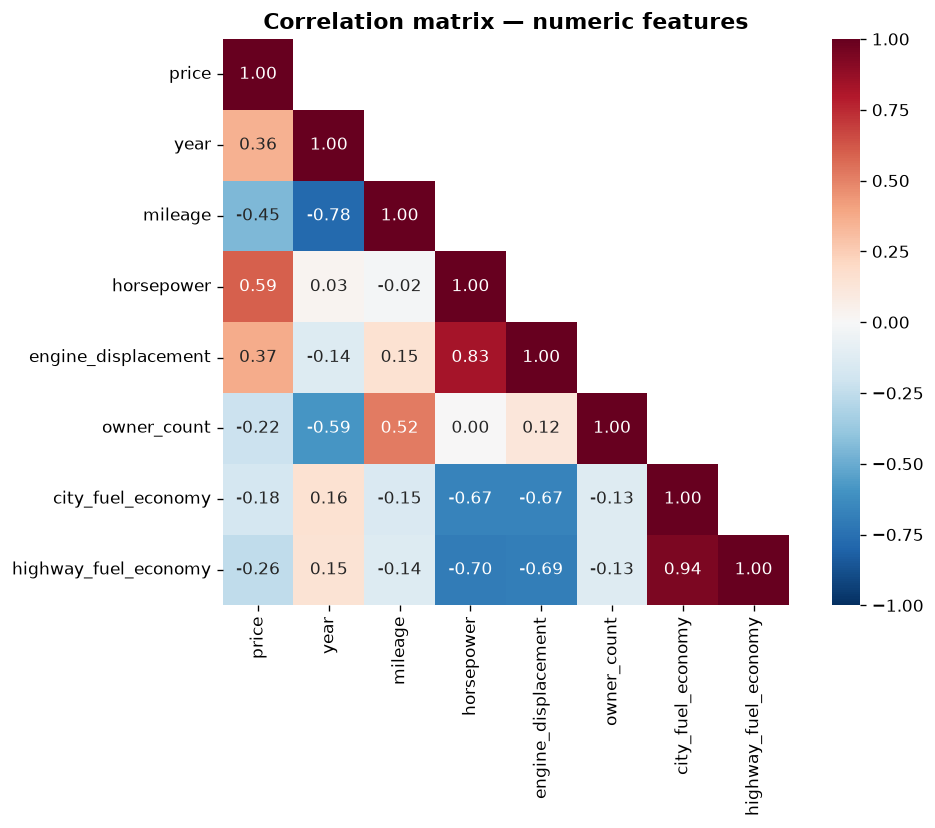

Correlations with price:
horsepower              0.594545
engine_displacement     0.368383
year                    0.357230
city_fuel_economy      -0.178118
owner_count            -0.218107
highway_fuel_economy   -0.256520
mileage                -0.449342


In [15]:
# Which numeric features correlate with price?
num_cols = ["price", "year", "mileage", "horsepower", 
            "engine_displacement", "owner_count",
            "city_fuel_economy", "highway_fuel_economy"]

corr_df = pdf_full[num_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_df, dtype=bool), k=1)  # upper triangle
sns.heatmap(corr_df, 
            annot=True, 
            fmt=".2f",
            cmap="RdBu_r",
            center=0,
            vmin=-1, vmax=1,
            mask=mask,
            ax=ax,
            square=True)

ax.set_title("Correlation matrix — numeric features",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("docs/plot_correlation.png", bbox_inches="tight")
plt.show()

# Print price correlations sorted
print("Correlations with price:")
print(corr_df["price"].drop("price").sort_values(ascending=False).to_string())


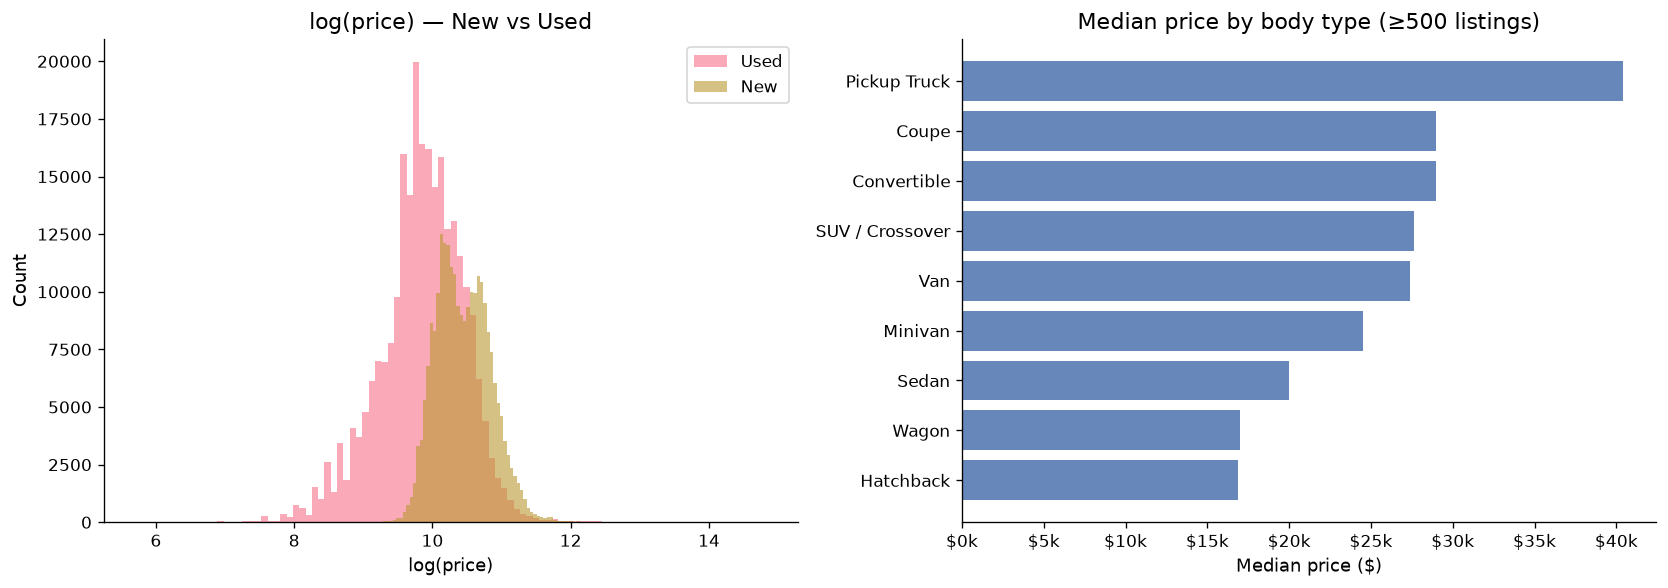

New vs Used — median prices:
is_new
Used    19442.5
New     33495.0
Name: price, dtype: float64

Body type counts and median prices:
                  median   count
body_type                       
Hatchback        16894.0   14843
Wagon            16995.0    6937
Sedan            19980.0  123277
Minivan          24497.0   13283
Van              27361.0    7970
SUV / Crossover  27655.0  236318
Convertible      28999.0    4419
Coupe            28999.0   11863
Pickup Truck     40402.0   78844


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── New vs Used price distribution ───────────────────────────────────────────
for label, grp in pdf_full.groupby("is_new"):
    tag = "New" if label else "Used"
    axes[0].hist(np.log(grp["price"].dropna()),
                 bins=100, alpha=0.6, label=tag, edgecolor="none")

axes[0].set_title("log(price) — New vs Used")
axes[0].set_xlabel("log(price)")
axes[0].set_ylabel("Count")
axes[0].legend()

# ── Median price by body type ─────────────────────────────────────────────────
body_price = (pdf_full.groupby("body_type")["price"]
              .agg(["median","count"])
              .query("count >= 500")
              .sort_values("median", ascending=True))

axes[1].barh(body_price.index, body_price["median"],
             color="#4C72B0", alpha=0.85)
axes[1].set_title("Median price by body type (≥500 listings)")
axes[1].set_xlabel("Median price ($)")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x,_: f"${x/1000:.0f}k"))

plt.tight_layout()
plt.savefig("docs/plot_segments.png", bbox_inches="tight")
plt.show()

# Stats
print("New vs Used — median prices:")
print(pdf_full.groupby("is_new")["price"].median().rename({True:"New", False:"Used"}))

print("\nBody type counts and median prices:")
print(body_price.to_string())

C:\Users\criya\AppData\Local\Temp\ipykernel_9600\2383702635.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(make_order, rotation=35, ha="right")


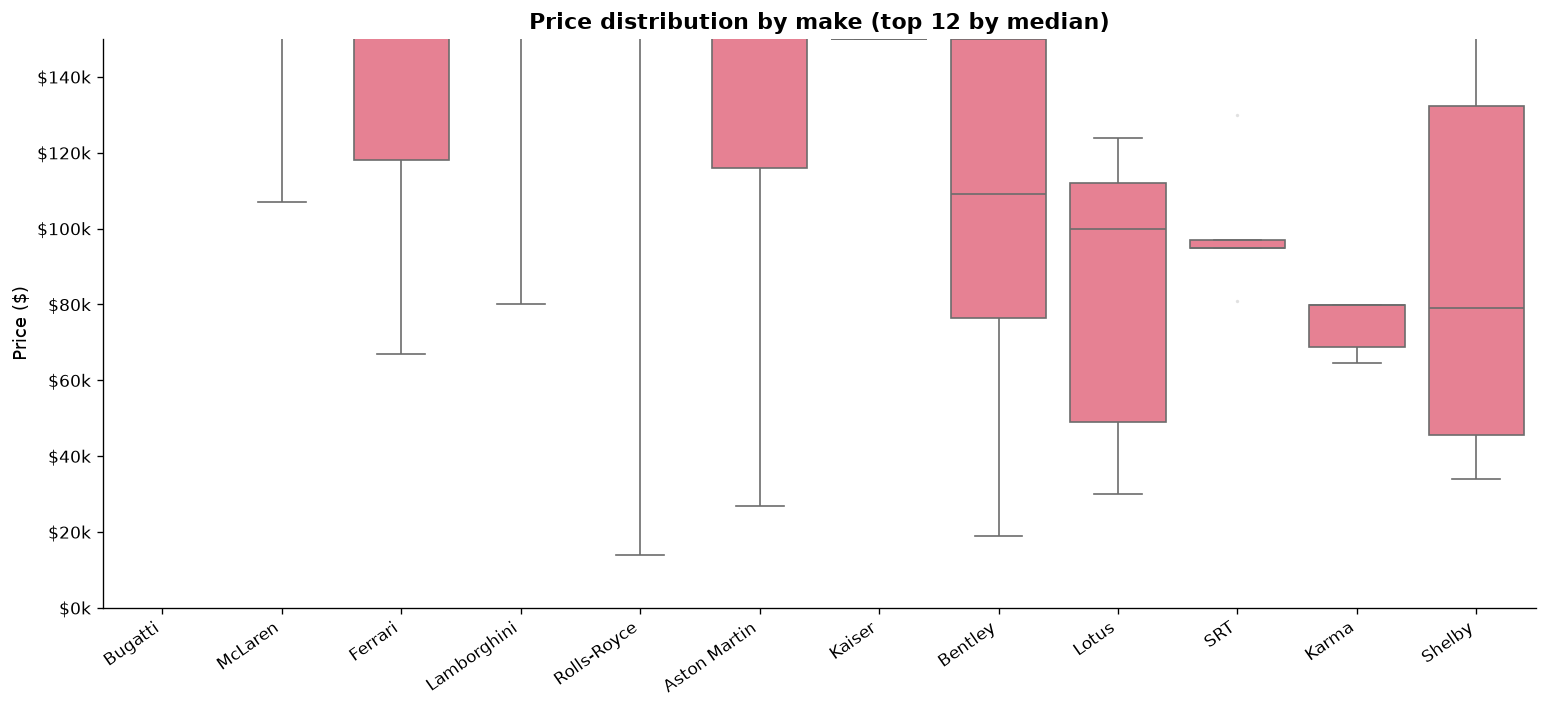

In [17]:
fig, ax = plt.subplots(figsize=(13, 6))

make_order = (pdf_full.groupby("make_name")["price"]
              .median()
              .sort_values(ascending=False)
              .head(12).index.tolist())

pdf_top12 = pdf_full[pdf_full["make_name"].isin(make_order)]

sns.boxplot(data=pdf_top12, x="make_name", y="price",
            order=make_order, ax=ax,
            flierprops={"marker":".", "alpha":0.2, "markersize":2})

ax.set_title("Price distribution by make (top 12 by median)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Price ($)")
ax.set_xticklabels(make_order, rotation=35, ha="right")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x,_: f"${x/1000:.0f}k"))
ax.set_ylim(0, 150_000)

plt.tight_layout()
plt.savefig("docs/plot_price_by_make.png", bbox_inches="tight")
plt.show()